# DATA 255 - Lab 3: Super Resolution
### Spring 2026 | San Jose State University
---
**Goal:** PSNR > 24.3 dB + Minimize NPU Latency

**Architecture:** TinySRNet (~1.2M params, channels=32, blocks=14)

**Drive Folder:** Lab3

## Cell 1: Install Packages

In [1]:
!pip install onnx onnxruntime onnxscript -q
print('All packages installed! ')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 11.9 MB/s eta 0:00:00
All packages installed! 


## Cell 2: Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted!')

Mounted at /content/drive
Drive mounted!


## Cell 3: Check GPU + Set Seeds

In [8]:
import torch
import numpy as np
import random
import os

SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

print(f'PyTorch version : {torch.__version__}')
print(f'GPU available   : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device    : {DEVICE}')

PyTorch version : 2.10.0+cpu
GPU available   : False
Using device    : cpu


## Cell 4: Unzip ALL 12 Dataset Files

In [9]:
import zipfile
import os
import time

DRIVE_PATH = '/content/drive/MyDrive/Lab3'
DATA_ROOT  = '/content/data'
os.makedirs(DATA_ROOT, exist_ok=True)

zip_files = {
    'L3_LR_train' : f'{DRIVE_PATH}/L3_LR_train.zip',
    'L3_LR_train1': f'{DRIVE_PATH}/L3_LR_train1.zip',
    'L3_LR_train2': f'{DRIVE_PATH}/L3_LR_train2.zip',
    'L3_LR_train3': f'{DRIVE_PATH}/L3_LR_train3.zip',
    'L3_LR_train4': f'{DRIVE_PATH}/L3_LR_train4.zip',
    'L3_HR_train' : f'{DRIVE_PATH}/L3_HR_train.zip',
    'L3_HR_train1': f'{DRIVE_PATH}/L3_HR_train1.zip',
    'L3_HR_train2': f'{DRIVE_PATH}/L3_HR_train2.zip',
    'L3_HR_train3': f'{DRIVE_PATH}/L3_HR_train3.zip',
    'L3_HR_train4': f'{DRIVE_PATH}/L3_HR_train4.zip',
    'L3_LR_valid' : f'{DRIVE_PATH}/L3_LR_valid.zip',
    'L3_HR_valid' : f'{DRIVE_PATH}/L3_HR_valid.zip',
}

for name, zip_path in zip_files.items():
    extract_path = os.path.join(DATA_ROOT, name)
    if os.path.exists(extract_path):
        print(f'Already extracted: {name} ')
        continue
    for attempt in range(3):
        try:
            print(f'Extracting {name}...')
            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall(extract_path)
            print(f'  Done ')
            break
        except OSError as e:
            print(f'  Error: {e} - Remounting...')
            time.sleep(3)
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

print('\nAll zips extracted!')

Extracting L3_LR_train...
  Done 
Extracting L3_LR_train1...
  Done 
Extracting L3_LR_train2...
  Done 
Extracting L3_LR_train3...
  Done 
Extracting L3_LR_train4...
  Done 
Extracting L3_HR_train...
  Done 
Extracting L3_HR_train1...
  Done 
Extracting L3_HR_train2...
  Done 
Extracting L3_HR_train3...
  Done 
Extracting L3_HR_train4...
  Done 
Extracting L3_LR_valid...
  Done 
Extracting L3_HR_valid...
  Done 

All zips extracted!


## Cell 5: Verify Dataset

In [10]:
from glob import glob

def get_images(folder):
    return sorted([
        f for f in glob(os.path.join(folder, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])

lr_train_dirs = [
    f'{DATA_ROOT}/L3_LR_train',  f'{DATA_ROOT}/L3_LR_train1',
    f'{DATA_ROOT}/L3_LR_train2', f'{DATA_ROOT}/L3_LR_train3',
    f'{DATA_ROOT}/L3_LR_train4'
]
hr_train_dirs = [
    f'{DATA_ROOT}/L3_HR_train',  f'{DATA_ROOT}/L3_HR_train1',
    f'{DATA_ROOT}/L3_HR_train2', f'{DATA_ROOT}/L3_HR_train3',
    f'{DATA_ROOT}/L3_HR_train4'
]

total_lr = sum(len(get_images(d)) for d in lr_train_dirs)
total_hr = sum(len(get_images(d)) for d in hr_train_dirs)
lr_val   = get_images(f'{DATA_ROOT}/L3_LR_valid')
hr_val   = get_images(f'{DATA_ROOT}/L3_HR_valid')

print(f'LR Train images : {total_lr}')
print(f'HR Train images : {total_hr}')
print(f'LR Val images   : {len(lr_val)}')
print(f'HR Val images   : {len(hr_val)}')
assert total_lr == total_hr, 'LR/HR mismatch!'
print(f'\nTotal train pairs: {total_lr} ')

LR Train images : 2217
HR Train images : 2217
LR Val images   : 110
HR Val images   : 110

Total train pairs: 2217 


## Cell 6: Imports

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import os
import random
import math
import shutil
import matplotlib.pyplot as plt
from glob import glob

print('All imports successful!')

All imports successful!


## Cell 7: Dataset Class

In [12]:
class SRDataset(Dataset):
    """
    Image Restoration Dataset for Lab 3.
    Both LR and HR are 256x256x3.
    Normalization: [0,1]
    """
    def __init__(self, lr_dir, hr_dir, augment=False):
        self.augment  = augment
        self.lr_files = sorted([
            f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        self.hr_files = sorted([
            f for f in glob(os.path.join(hr_dir, '**', '*'), recursive=True)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])
        assert len(self.lr_files) == len(self.hr_files), \
            f'Mismatch: {len(self.lr_files)} LR vs {len(self.hr_files)} HR'

        self.transform = transforms.Compose([
            transforms.Resize((256, 256), Image.BILINEAR),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr_img = Image.open(self.lr_files[idx]).convert('RGB')
        hr_img = Image.open(self.hr_files[idx]).convert('RGB')

        if self.augment:
            if random.random() > 0.5:
                lr_img = TF.hflip(lr_img)
                hr_img = TF.hflip(hr_img)
            if random.random() > 0.5:
                lr_img = TF.vflip(lr_img)
                hr_img = TF.vflip(hr_img)
            if random.random() > 0.5:
                angle  = random.choice([90, 180, 270])
                lr_img = TF.rotate(lr_img, angle)
                hr_img = TF.rotate(hr_img, angle)
            if random.random() > 0.5:
                factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_brightness(lr_img, factor)
                hr_img = TF.adjust_brightness(hr_img, factor)

        return self.transform(lr_img), self.transform(hr_img)

print('SRDataset ready!')

SRDataset ready!


## Cell 8: Load ALL Training Data

In [13]:
train_datasets = []

for lr_dir, hr_dir in zip(lr_train_dirs, hr_train_dirs):
    ds = SRDataset(lr_dir, hr_dir, augment=True)
    train_datasets.append(ds)
    print(f'Loaded: {os.path.basename(lr_dir)} -> {len(ds)} pairs')

full_train_dataset = ConcatDataset(train_datasets)

val_dataset = SRDataset(
    f'{DATA_ROOT}/L3_LR_valid',
    f'{DATA_ROOT}/L3_HR_valid',
    augment=False
)

print(f'\nTotal training pairs : {len(full_train_dataset)}')
print(f'Total val pairs      : {len(val_dataset)}')

Loaded: L3_LR_train -> 404 pairs
Loaded: L3_LR_train1 -> 437 pairs
Loaded: L3_LR_train2 -> 466 pairs
Loaded: L3_LR_train3 -> 456 pairs
Loaded: L3_LR_train4 -> 454 pairs

Total training pairs : 2217
Total val pairs      : 110


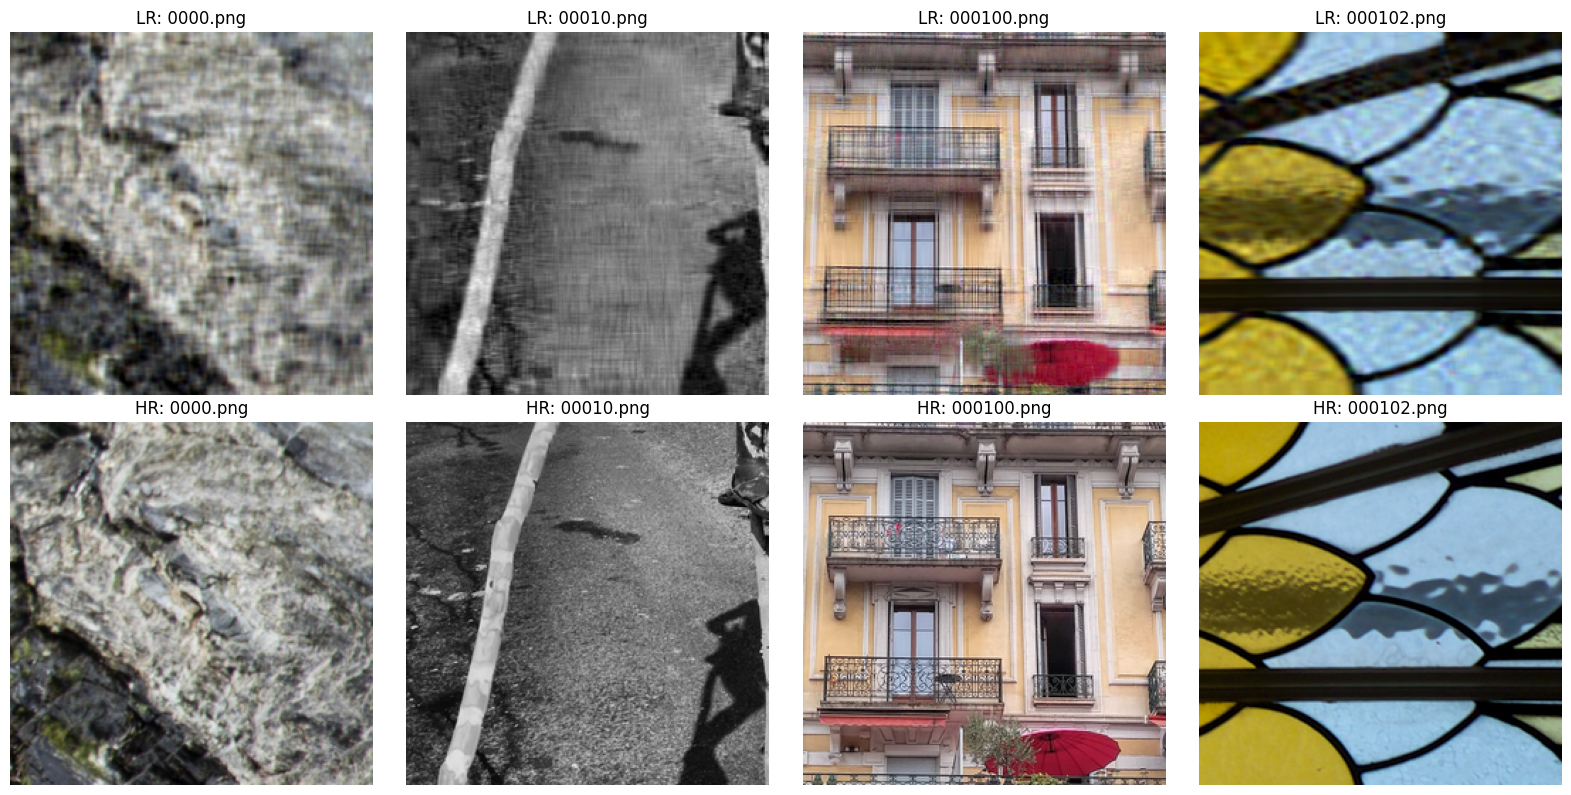

In [ ]:
# Check if pairs are matching correctly
import matplotlib.pyplot as plt
from PIL import Image
import os

# Get first val pair
lr_files = sorted([f for f in glob(
    f'{DATA_ROOT}/L3_LR_valid/**/*', recursive=True)
    if f.endswith(('.png','.jpg','.jpeg'))])
hr_files = sorted([f for f in glob(
    f'{DATA_ROOT}/L3_HR_valid/**/*', recursive=True)
    if f.endswith(('.png','.jpg','.jpeg'))])

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i in range(4):
    lr = Image.open(lr_files[i])
    hr = Image.open(hr_files[i])
    axes[0,i].imshow(lr)
    axes[0,i].set_title(f'LR: {os.path.basename(lr_files[i])}')
    axes[0,i].axis('off')
    axes[1,i].imshow(hr)
    axes[1,i].set_title(f'HR: {os.path.basename(hr_files[i])}')
    axes[1,i].axis('off')

plt.tight_layout()
plt.show()

## Cell 9: Hyperparameters & DataLoaders

In [14]:
BATCH_SIZE    = 16
LEARNING_RATE = 2e-4
NUM_EPOCHS    = 350
NUM_WORKERS   = 2
SAVE_EVERY    = 10

SAVE_DIR = '/content/drive/MyDrive/Lab3/outputs'
os.makedirs(SAVE_DIR, exist_ok=True)

train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')
print(f'Batch size    : {BATCH_SIZE}')
print(f'Epochs        : {NUM_EPOCHS}')
print(f'Learning rate : {LEARNING_RATE}')
print(f'Save dir      : {SAVE_DIR}')

Train batches : 139
Val batches   : 7
Batch size    : 16
Epochs        : 350
Learning rate : 0.0002
Save dir      : /content/drive/MyDrive/Lab3/outputs


## Cell 10: TinySRNet Model


In [15]:
# ── Depthwise Separable Conv Block ────────────────────────────────────────────
class DSConvBlock(nn.Module):
    """
    Depthwise Separable Conv + BN + ReLU.
    Fast NPU ops for low latency.
    """
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.dw  = nn.Conv2d(
            in_ch, in_ch, 3,
            padding=1, groups=in_ch, bias=False
        )
        self.pw  = nn.Conv2d(in_ch, out_ch, 1, bias=False)
        self.bn  = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.bn(self.pw(self.dw(x))))


# ── Tiny Residual Block ───────────────────────────────────────────────────────
class TinyResBlock(nn.Module):
    """
    Lightweight residual block with DSConv.
    """
    def __init__(self, channels):
        super().__init__()
        self.conv1 = DSConvBlock(channels, channels)
        self.conv2 = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        return self.relu(out + x)


# ── Main Model: TinySRNet ─────────────────────────────────────────────────────
class TinySRNet(nn.Module):
    """
    Lightweight SR Network for Lab 3.
    Input : [B, 3, 256, 256] degraded LR
    Output: [B, 3, 256, 256] restored HR
    ~1.2M params, DSConv for fast NPU inference
    """
    def __init__(self, channels=32, num_blocks=14):
        super().__init__()

        self.head = nn.Sequential(
            nn.Conv2d(3, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )
        self.body = nn.Sequential(
            *[TinyResBlock(channels) for _ in range(num_blocks)]
        )
        self.body_end = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )
        self.tail = nn.Sequential(
            DSConvBlock(channels, channels // 2),
            nn.Conv2d(channels // 2, 3, 1)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        lr_input = x
        head_out = self.head(x)
        body_out = self.body_end(self.body(head_out))
        features = head_out + body_out
        residual = self.tail(features)
        return torch.clamp(lr_input + residual, 0, 1)


# Build model
model = TinySRNet(channels=64, num_blocks=16).to(DEVICE)

dummy = torch.randn(1, 3, 256, 256).to(DEVICE)
with torch.no_grad():
    out = model(dummy)

print(f'Input  shape : {dummy.shape}')
print(f'Output shape : {out.shape}')
total = sum(p.numel() for p in model.parameters())
print(f'Total params : {total:,}')
print(f'Target PSNR  : > 24.3 dB')
print(f'Target latency: < 6ms on NPU')

Input  shape : torch.Size([1, 3, 256, 256])
Output shape : torch.Size([1, 3, 256, 256])
Total params : 710,307
Target PSNR  : > 24.3 dB
Target latency: < 6ms on NPU


## Cell 11: Test ONNX Export Early

In [ ]:
import onnx

TEST_ONNX   = '/content/test_export.onnx'
model.eval()
dummy_input = torch.randn(1, 3, 256, 256).to(DEVICE)

try:
    torch.onnx.export(
        model, dummy_input, TEST_ONNX,
        export_params=True, opset_version=11,
        do_constant_folding=True,
        input_names=['input'], output_names=['output'],
        dynamic_axes=None, verbose=False
    )
    onnx_model = onnx.load(TEST_ONNX)
    onnx.save_model(onnx_model, TEST_ONNX, save_as_external_data=False)
    onnx.checker.check_model(onnx.load(TEST_ONNX))
    size_mb = os.path.getsize(TEST_ONNX) / 1e6
    print(f'ONNX export :  Success')
    print(f'Size        : {size_mb:.2f} MB')
    print(f'Safe to train!')
except Exception as e:
    print(f'ONNX FAILED : {e}')

W0425 05:46:21.075000 6595 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0425 05:46:21.855000 6595 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0425 05:46:21.857000 6595 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio

ONNX export :  Success
Size        : 3.02 MB
Safe to train!


## Cell 12: Loss + PSNR

In [ ]:
criterion = nn.L1Loss()

def compute_psnr(pred, target):
    mse = torch.mean((pred.clamp(0,1) - target.clamp(0,1)) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * math.log10(1.0 / math.sqrt(mse.item()))

print('Loss     : L1')
print('Target   : PSNR > 24.3 dB')
print('Baseline : 23.1 dB')

Loss     : L1
Target   : PSNR > 24.3 dB
Baseline : 23.1 dB


## Cell 13: Optimizer & Scheduler

In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.999),
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
)

print('Optimizer : Adam')
print('Scheduler : CosineAnnealingLR')

Optimizer : Adam
Scheduler : CosineAnnealingLR


## Cell 14: Training Loop

In [ ]:
train_losses = []
val_psnrs    = []
best_psnr    = 0.0

print('=' * 65)
print('Starting Training — TinySRNet (~700K params)')
print('Target: PSNR > 24.3 dB + Low Latency')
print('Baseline: 23.1 dB')
print('=' * 65)

for epoch in range(1, NUM_EPOCHS + 1):

    model.train()
    epoch_loss = 0.0

    for lr_imgs, hr_imgs in train_loader:
        lr_imgs = lr_imgs.to(DEVICE)
        hr_imgs = hr_imgs.to(DEVICE)
        optimizer.zero_grad()
        pred = model(lr_imgs)
        loss = criterion(pred, hr_imgs)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    total_psnr = 0.0

    with torch.no_grad():
        for lr_imgs, hr_imgs in val_loader:
            lr_imgs = lr_imgs.to(DEVICE)
            hr_imgs = hr_imgs.to(DEVICE)
            pred    = model(lr_imgs)
            for i in range(pred.shape[0]):
                total_psnr += compute_psnr(pred[i], hr_imgs[i])

    avg_psnr   = total_psnr / len(val_dataset)
    val_psnrs.append(avg_psnr)
    scheduler.step()
    current_lr = optimizer.param_groups[0]['lr']

    print(f'Epoch [{epoch:03d}/{NUM_EPOCHS}] | '
          f'Loss: {avg_train_loss:.4f} | '
          f'Val PSNR: {avg_psnr:.2f} dB | '
          f'LR: {current_lr:.2e}'
          f'{" ✅ > 24.3!" if avg_psnr > 24.3 else ""}')

    if avg_psnr > best_psnr:
        best_psnr = avg_psnr
        torch.save({
            'epoch'               : epoch,
            'model_state_dict'    : model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_psnr'           : best_psnr,
            'architecture'        : 'TinySRNet',
            'channels'            : 32,
            'num_blocks'          : 14
        }, os.path.join(SAVE_DIR, 'best_model.pth'))
        print(f'  --> New best! PSNR: {best_psnr:.2f} dB saved!')

    if epoch % SAVE_EVERY == 0:
        torch.save({
            'epoch'           : epoch,
            'model_state_dict': model.state_dict(),
            'psnr'            : avg_psnr,
        }, os.path.join(SAVE_DIR, f'checkpoint_epoch_{epoch}.pth'))
        print(f'  --> Checkpoint saved at epoch {epoch}')

print('=' * 65)
print(f'Training complete! Best PSNR: {best_psnr:.2f} dB')
print(f'Target 24.3 dB: {" PASSED" if best_psnr > 24.3 else " NOT reached"}')
print('=' * 65)

Starting Training — TinySRNet (~700K params)
Target: PSNR > 24.3 dB + Low Latency
Baseline: 23.1 dB
Epoch [001/350] | Loss: 0.1020 | Val PSNR: 19.41 dB | LR: 2.00e-04
  --> New best! PSNR: 19.41 dB saved!
Epoch [002/350] | Loss: 0.0681 | Val PSNR: 20.58 dB | LR: 2.00e-04
  --> New best! PSNR: 20.58 dB saved!
Epoch [003/350] | Loss: 0.0588 | Val PSNR: 21.51 dB | LR: 2.00e-04
  --> New best! PSNR: 21.51 dB saved!
Epoch [004/350] | Loss: 0.0545 | Val PSNR: 22.06 dB | LR: 2.00e-04
  --> New best! PSNR: 22.06 dB saved!
Epoch [005/350] | Loss: 0.0523 | Val PSNR: 22.21 dB | LR: 2.00e-04
  --> New best! PSNR: 22.21 dB saved!
Epoch [006/350] | Loss: 0.0513 | Val PSNR: 22.64 dB | LR: 2.00e-04
  --> New best! PSNR: 22.64 dB saved!
Epoch [007/350] | Loss: 0.0500 | Val PSNR: 22.09 dB | LR: 2.00e-04
Epoch [008/350] | Loss: 0.0494 | Val PSNR: 22.76 dB | LR: 2.00e-04
  --> New best! PSNR: 22.76 dB saved!
Epoch [009/350] | Loss: 0.0490 | Val PSNR: 22.82 dB | LR: 2.00e-04
  --> New best! PSNR: 22.82 dB 

## Cell 15: Plot Training Curves

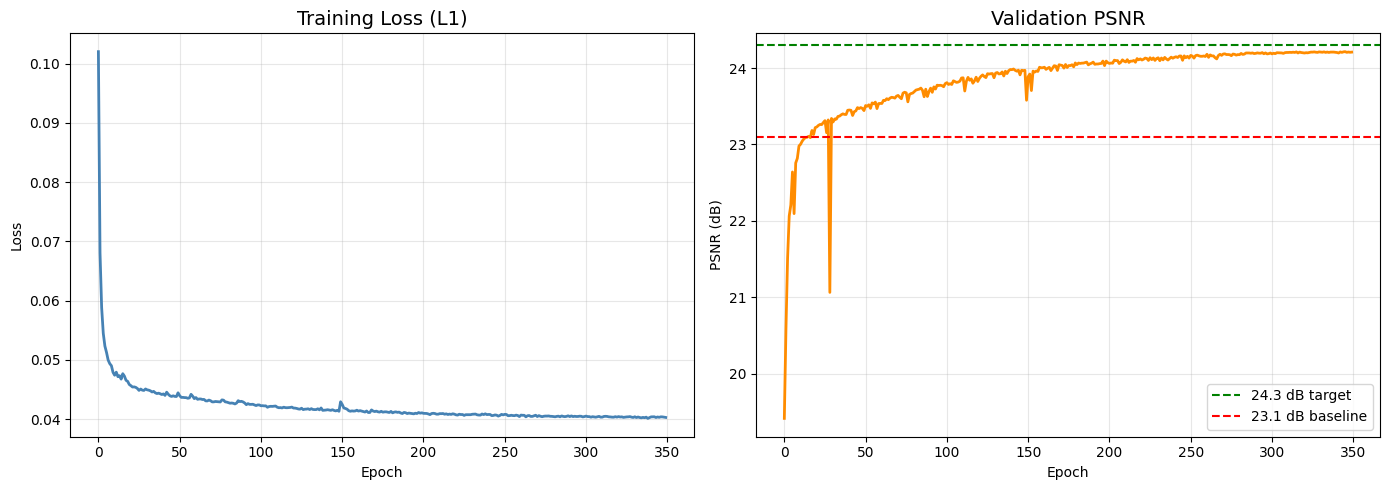

Saved to Drive!


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', linewidth=2)
ax1.set_title('Training Loss (L1)', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(val_psnrs, color='darkorange', linewidth=2)
ax2.axhline(y=24.3, color='green', linestyle='--', label='24.3 dB target')
ax2.axhline(y=23.1, color='red',   linestyle='--', label='23.1 dB baseline')
ax2.set_title('Validation PSNR', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('PSNR (dB)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()
print('Saved to Drive!')

## Cell 16: Visualize Predictions

Best model: Epoch 346 | PSNR: 24.21 dB


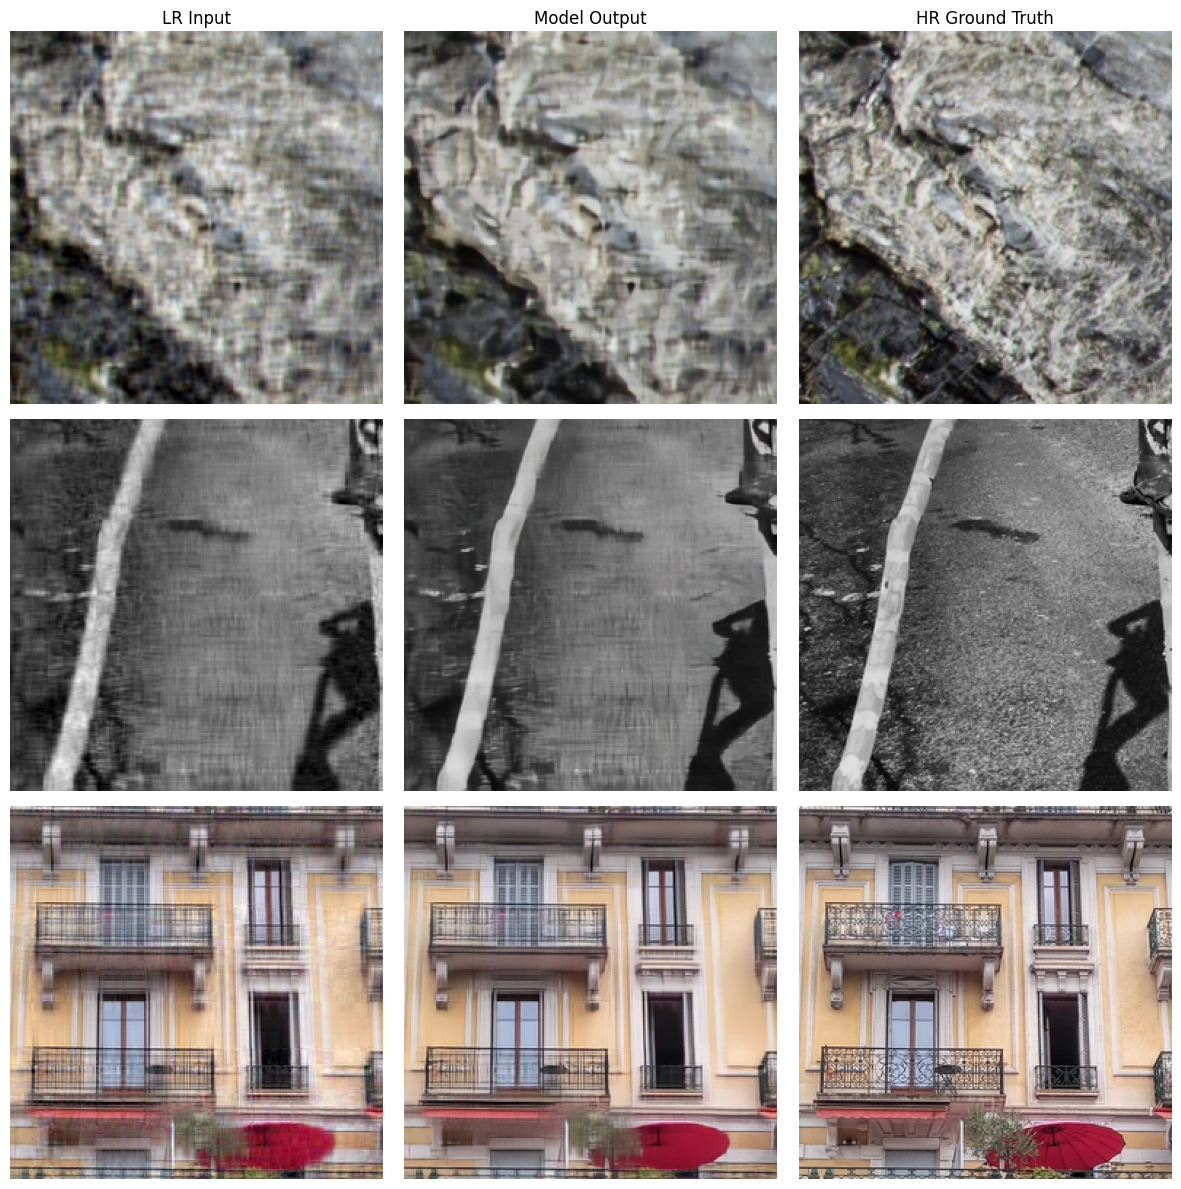

Predictions saved!


In [ ]:
checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'), map_location=DEVICE
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Best model: Epoch {checkpoint["epoch"]} | PSNR: {checkpoint["best_psnr"]:.2f} dB')

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0,0].set_title('LR Input',        fontsize=12)
axes[0,1].set_title('Model Output',    fontsize=12)
axes[0,2].set_title('HR Ground Truth', fontsize=12)

lr_batch, hr_batch = next(iter(val_loader))
lr_batch = lr_batch.to(DEVICE)
hr_batch = hr_batch.to(DEVICE)

with torch.no_grad():
    pred_batch = model(lr_batch)

for i in range(3):
    lr_np   = lr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    pred_np = pred_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    hr_np   = hr_batch[i].cpu().permute(1,2,0).numpy().clip(0,1)
    psnr_v  = compute_psnr(pred_batch[i], hr_batch[i])

    axes[i,0].imshow(lr_np);   axes[i,0].axis('off')
    axes[i,1].imshow(pred_np); axes[i,1].set_xlabel(f'PSNR: {psnr_v:.2f} dB'); axes[i,1].axis('off')
    axes[i,2].imshow(hr_np);   axes[i,2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'sample_predictions.png'), dpi=150)
plt.show()
print('Predictions saved!')

## Cell 17: Save Calibration Images

In [ ]:
CALIB_DIR = os.path.join(SAVE_DIR, 'calibration_images')
os.makedirs(CALIB_DIR, exist_ok=True)

NUM_CALIB_PER_ZIP = 10
calib_count = 0

for lr_dir in lr_train_dirs:
    files = sorted([
        f for f in glob(os.path.join(lr_dir, '**', '*'), recursive=True)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ])
    step     = max(1, len(files) // NUM_CALIB_PER_ZIP)
    selected = files[::step][:NUM_CALIB_PER_ZIP]

    for f in selected:
        img = Image.open(f).convert('RGB')
        img = img.resize((256, 256), Image.BILINEAR)
        img.save(os.path.join(CALIB_DIR, f'calib_{calib_count:03d}.jpg'))
        calib_count += 1

print(f'Saved {calib_count} calibration images ')
print(f'Location: {CALIB_DIR}')

Saved 50 calibration images 
Location: /content/drive/MyDrive/Lab3/outputs/calibration_images


## Cell 18: Export ONNX — Single File

In [17]:
import torch
import onnx
import shutil
import os



checkpoint = torch.load(
    os.path.join(SAVE_DIR, 'best_model.pth'),
    map_location='cpu'
)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.cpu().eval()

dummy_input = torch.randn(1, 3, 256, 256)

# Force legacy exporter = opset 11
with torch.no_grad():
    torch.onnx.export(
        model,
        dummy_input,
        LOCAL_ONNX,
        export_params=True,
        opset_version=11,
        do_constant_folding=True,
        input_names=['input'],
        output_names=['output'],
        dynamic_axes=None,
        verbose=False,
        dynamo=False
    )

onnx_model = onnx.load(LOCAL_ONNX)
onnx.save_model(onnx_model, LOCAL_ONNX, save_as_external_data=False)
onnx.checker.check_model(onnx.load(LOCAL_ONNX))

size_mb = os.path.getsize(LOCAL_ONNX) / 1e6
loaded = onnx.load(LOCAL_ONNX)
print(f'Opset : {loaded.opset_import[0].version}')
print(f'Size  : {size_mb:.2f} MB')

shutil.copy2(LOCAL_ONNX, DRIVE_ONNX)
print(f'Saved to Drive ✅')

/tmp/ipykernel_4305/2937811153.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Opset : 11
Size  : 2.85 MB
Saved to Drive ✅
